In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", np.unique(y))

Dataset shape: (1797, 64)
Target shape: (1797,)
Classes: [0 1 2 3 4 5 6 7 8 9]


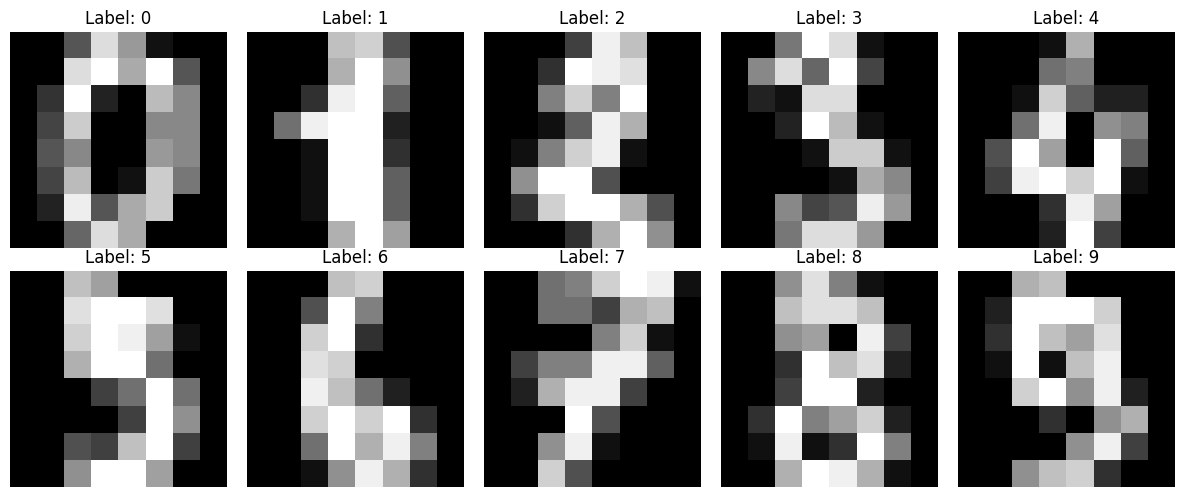

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1437
Testing samples: 360


In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [6]:
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

svm_model.fit(X_train, y_train)

print("SVM model training completed.")

SVM model training completed.


In [7]:
y_pred = svm_model.predict(X_test)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])

Actual labels:    [5 2 8 1 7 2 6 2 6 5]
Predicted labels: [5 2 8 1 7 2 6 2 6 5]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Classification Accuracy: {:.2f}%".format(accuracy * 100))

SVM Classification Accuracy: 98.06%


In [9]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.95      0.97      0.96        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



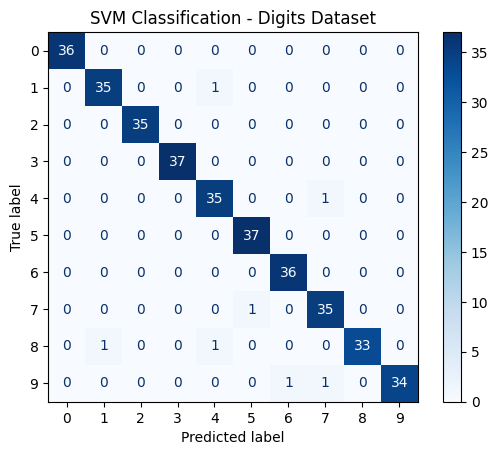

In [10]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=digits.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SVM Classification - Digits Dataset")
plt.show()

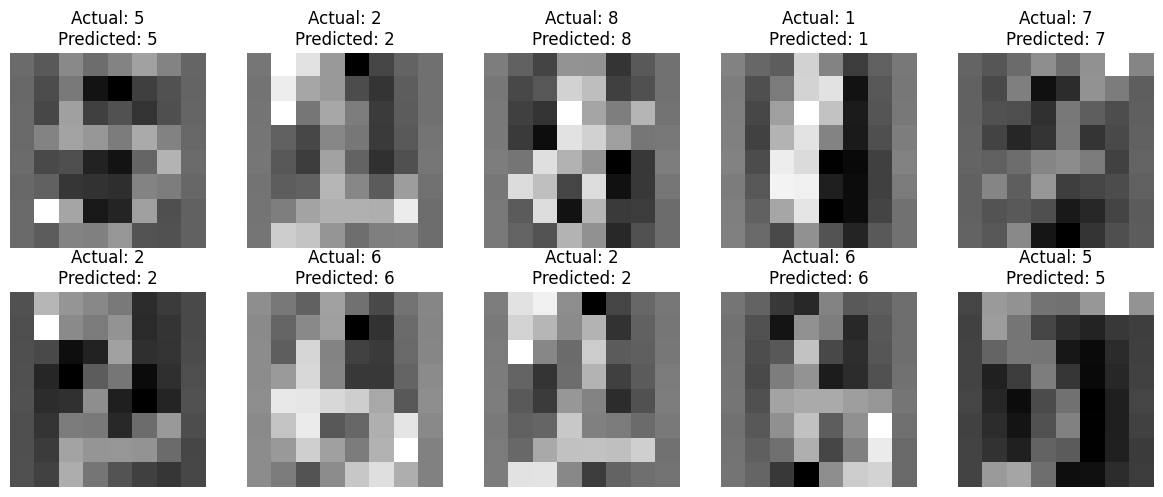

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray")
    ax.set_title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

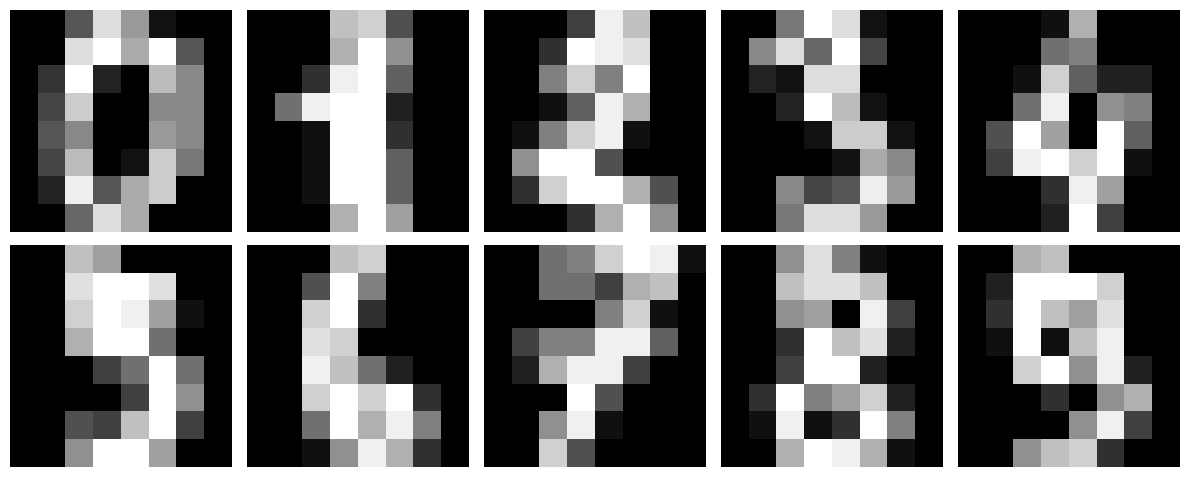

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[X_test.shape[0] * 0 + i], cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()